In [ ]:
# DATASET : vgchartz-2_1_2024.csv
from google.colab import files
uploaded = files.upload()

Saving vgchartz-2_1_2024.csv to vgchartz-2_1_2024.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

Data = pd.read_csv('vgchartz-2_1_2024.csv')
df = pd.DataFrame(data = Data)
print(df.head())


print(df["jp_sales"].mean())

                                             img  \
0  /games/boxart/full_9916295AmericaFrontccc.jpg   
1  /games/boxart/full_5995252AmericaFrontccc.jpg   
2  /games/boxart/full_5208890AmericaFrontccc.jpg   
3  /games/boxart/full_6456368AmericaFrontccc.jpg   
4  /games/boxart/full_3731874AmericaFrontccc.jpg   

                           title console   genre  publisher         developer  \
0               Assassin's Creed  Series  Action    Ubisoft           Ubisoft   
1                Animal Crossing  Series  Action   Nintendo          Nintendo   
2  Animal Crossing: New Horizons      NS  Action   Nintendo          Nintendo   
3                 Age of Empires  Series  Action  Microsoft  Ensemble Studios   
4                     Ace Combat  Series  Action      Namco             Namco   

   vg_score  critic_score  user_score  total_shipped  total_sales  na_sales  \
0       NaN           NaN         NaN         200.00          NaN       NaN   
1       NaN           NaN         NaN     

In [ ]:
print(df.describe())

          vg_score  critic_score  user_score  total_shipped   total_sales  \
count  1043.000000   4334.000000  257.000000    4303.000000  11797.000000   
mean      7.627709      7.387425    8.474708       5.028706      0.550432   
std       1.338636      1.367820    1.237067      21.645171      0.982478   
min       2.000000      1.500000    2.000000       0.070000      0.070000   
25%       7.000000      6.600000    8.000000       0.260000      0.130000   
50%       8.000000      7.600000    8.800000       1.000000      0.260000   
75%       8.600000      8.400000    9.300000       3.000000      0.560000   
max       9.700000     10.000000   10.000000     520.000000     20.320000   

          na_sales     jp_sales    pal_sales   other_sales  
count  9941.000000  4008.000000  9271.000000  10622.000000  
mean      0.333056     0.155322     0.205720      0.061593  
std       0.546074     0.201680     0.454762      0.149068  
min       0.000000     0.000000     0.000000      0.000000  
2

In [ ]:
np.argmax(df['total_sales'])

176

In [ ]:
df.iloc[[176]]

,img,title,console,genre,publisher,developer,vg_score,critic_score,user_score,total_shipped,total_sales,na_sales,jp_sales,pal_sales,other_sales,release_date,last_update
176,/games/boxart/full_6510540AmericaFrontccc.jpg,Grand Theft Auto V,PS3,Action,Rockstar Games,Rockstar North,9.5,9.4,NaN,NaN,20.32,6.37,0.99,9.85,3.12,2013-09-17,NaN


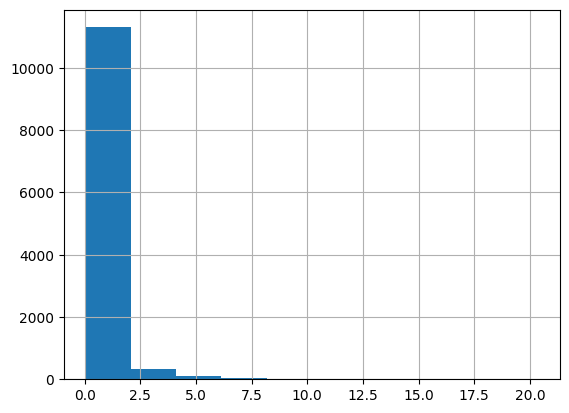

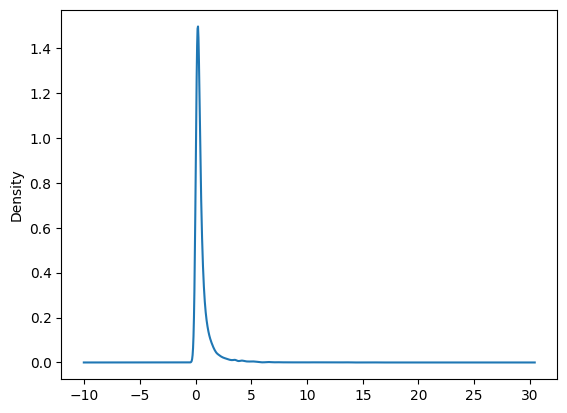

In [ ]:
df["total_sales"].hist()
plt.show()


df["total_sales"].plot(kind = 'density')
plt.show()

In [5]:
def extract_year(df, date_column):
    df['Year'] = pd.to_datetime(df[date_column]).dt.year
    return df

In [6]:
pd.to_datetime(df.iloc[[176]]['release_date']).dt.year

,release_date
176,2013


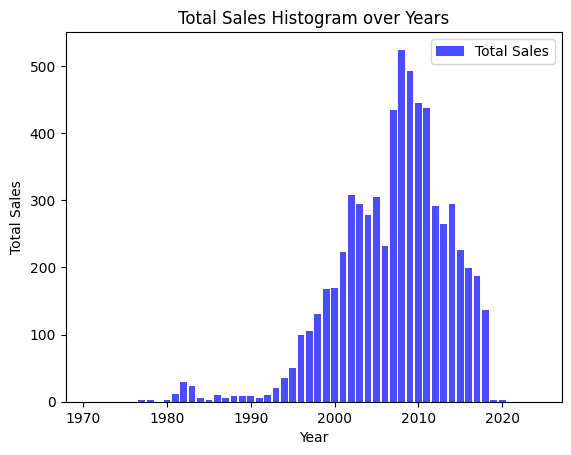

In [7]:
import matplotlib.pyplot as plt

df_temp =  extract_year(df, 'release_date')
#plt.bar(df_temp['Year'],df['total_sales'].groupby(by=["Year"]).sum(), color='blue', alpha=0.7, label='Total Sales')
# Groupage par année et somme  des ventes totales
sales_per_year = df.groupby(df_temp['Year'])['total_sales'].sum()

plt.bar(sales_per_year.index, sales_per_year.values, color='blue', alpha=0.7, label='Total Sales')


plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.title('Total Sales Histogram over Years')
plt.legend()


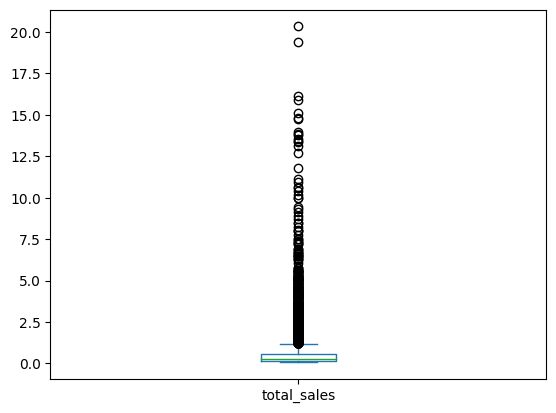

In [ ]:

df["total_sales"].plot(kind='box' )
plt.show()

<Axes: xlabel='genre', ylabel='pal_sales'>

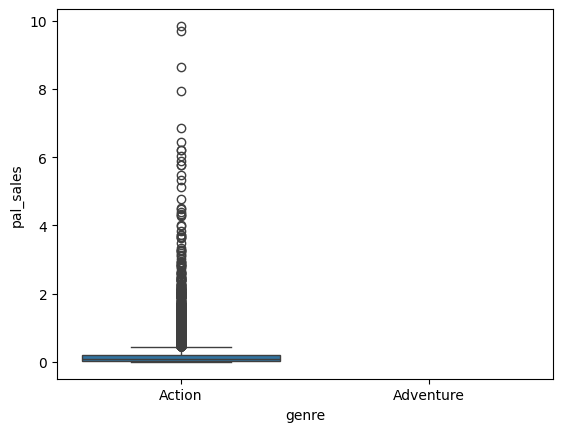

In [8]:
import seaborn as sns

#sns.set(rc={'figure.figsize':(11.7,8.27)})

#create boxplot by group
sns.boxplot(x='genre', y='pal_sales', data=df)

In [ ]:
df = df[df['genre'] == 'Action']

In [10]:
df_Ubisoft = df["pal_sales"][df["publisher"]== "Ubisoft"]
df_Nintendo = df["pal_sales"][df["publisher"]== "Nintendo"]

In [11]:
df_Nintendo

,pal_sales
1,NaN
2,NaN
6,NaN
10,NaN
38,NaN
...,...
16079,NaN
16084,NaN
16089,NaN
16090,NaN


In [ ]:
var = np.var(df_Ubisoft)
var2 = np.var(df_Nintendo)
print(var)
print(var2)

0.2095141760426728
0.010761387075638817


In [ ]:
var = np.var(df_Ubisoft,ddof=1)
var2 = np.var(df_Nintendo,ddof=1)
print(var)
print(var2)

0.209823650453371
0.010814661269082574


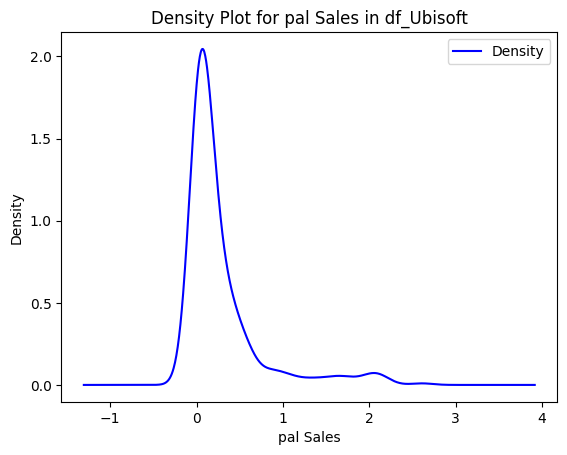

In [ ]:
df_Ubisoft.plot(kind='kde', color='blue', label='Density')

plt.xlabel('pal Sales')
plt.ylabel('Density')
plt.title('Density Plot for pal Sales in df_Ubisoft')

plt.legend()
plt.show()

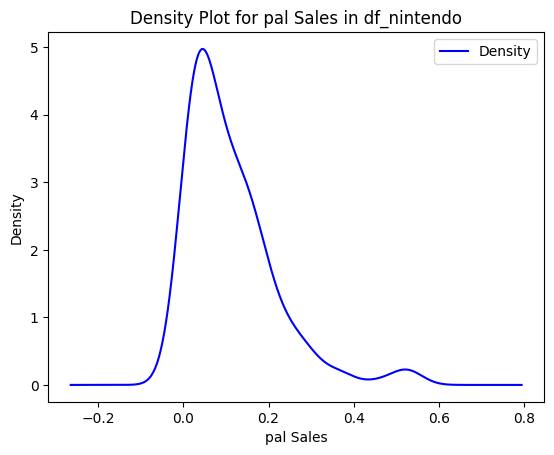

In [ ]:
df_Nintendo.plot(kind='kde', color='blue', label='Density')

plt.xlabel('pal Sales')
plt.ylabel('Density')
plt.title('Density Plot for pal Sales in df_nintendo')

plt.legend()
plt.show()

In [13]:
shapiro_test = stats.shapiro(df_Ubisoft)

shapiro_test2 = stats.shapiro(df_Nintendo)

print(shapiro_test)
print(shapiro_test2)

ShapiroResult(statistic=nan, pvalue=nan)
ShapiroResult(statistic=nan, pvalue=nan)


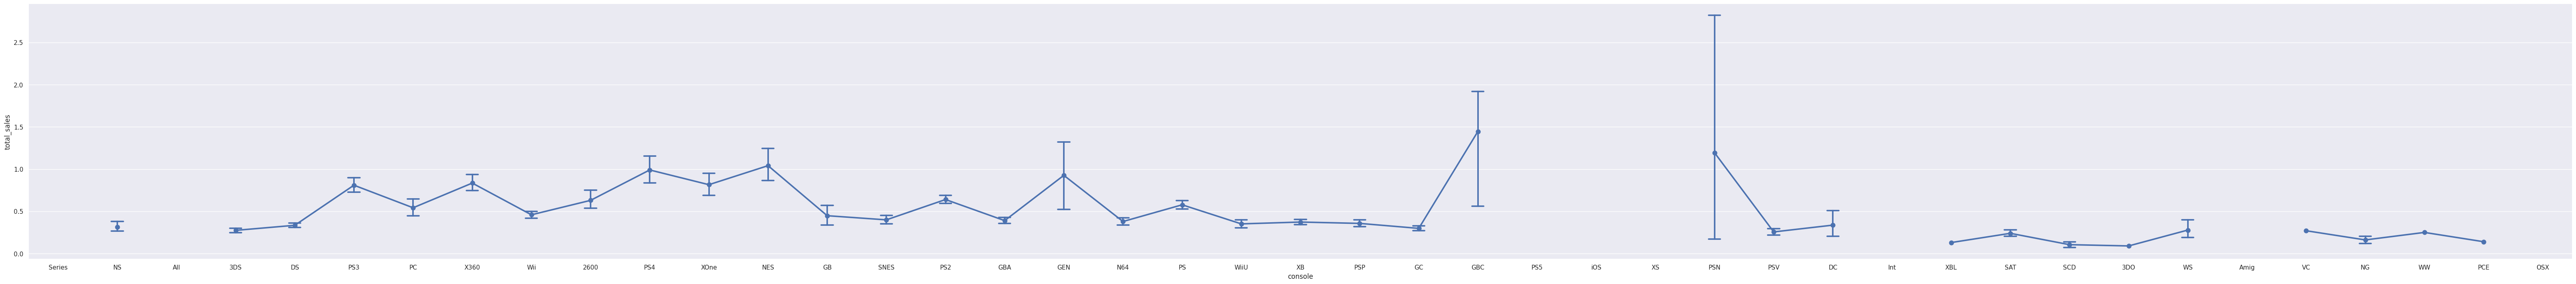

<Figure size 8170x827 with 0 Axes>

In [12]:
sns.set(rc={'figure.figsize':(81.7,8.27)})
ax = sns.pointplot(x=df["console"] ,  y=df["total_sales"], data=df, estimator=np.mean,capsize=.2)
plt.figure()
plt.show()

In [ ]:
for console in df['console'].unique():
    print(console)
    if(len(df["total_sales"][df["console"]== console])>3):
          print(stats.shapiro(df["total_sales"][df["console"]== console]))

Series
ShapiroResult(statistic=nan, pvalue=1.0)
NS
ShapiroResult(statistic=nan, pvalue=1.0)
All
ShapiroResult(statistic=nan, pvalue=1.0)
3DS
ShapiroResult(statistic=nan, pvalue=1.0)
DS
ShapiroResult(statistic=nan, pvalue=1.0)
PS3
ShapiroResult(statistic=nan, pvalue=1.0)
PC
ShapiroResult(statistic=nan, pvalue=1.0)
X360
ShapiroResult(statistic=nan, pvalue=1.0)
Wii
ShapiroResult(statistic=nan, pvalue=1.0)
2600
ShapiroResult(statistic=nan, pvalue=1.0)
PS4
ShapiroResult(statistic=nan, pvalue=1.0)
XOne
ShapiroResult(statistic=nan, pvalue=1.0)
NES
ShapiroResult(statistic=nan, pvalue=1.0)
GB
ShapiroResult(statistic=nan, pvalue=1.0)
SNES
ShapiroResult(statistic=nan, pvalue=1.0)
PS2
ShapiroResult(statistic=nan, pvalue=1.0)
GBA
ShapiroResult(statistic=nan, pvalue=1.0)
GEN
ShapiroResult(statistic=nan, pvalue=1.0)
N64
ShapiroResult(statistic=nan, pvalue=1.0)
PS
ShapiroResult(statistic=nan, pvalue=1.0)
WiiU
ShapiroResult(statistic=nan, pvalue=1.0)
XB
ShapiroResult(statistic=nan, pvalue=1.0)
PSP
Shap

In [ ]:
print(stats.shapiro(df["total_sales"]))



ShapiroResult(statistic=nan, pvalue=1.0)


/usr/local/lib/python3.10/dist-packages/scipy/stats/_morestats.py:1882: UserWarning: p-value may not be accurate for N > 5000.
  warnings.warn("p-value may not be accurate for N > 5000.")


In [ ]:
mean= df["total_sales"].mean()

sd = np.std(df["total_sales"])

x1 = np.random.normal(loc=mean,scale=sd,size= len(df))
ks_test = stats.kstest(df["total_sales"],x1)
print(ks_test)


KstestResult(statistic=0.3097196261682243, pvalue=0.0, statistic_location=0.06992338830013906, statistic_sign=-1)


In [ ]:
liste_publishers = df['publisher'].unique()

# Affichez la liste des publishers
print(liste_publishers)

['Ubisoft' 'Nintendo' 'Microsoft' 'Namco' '505 Games' 'Kunos Simulazioni'
 'Capcom' 'Studio Wildcard' 'Koei Tecmo' 'Microsoft Studios'
 'GT Interactive' 'Bohemia Interactive' 'Fox Interactive'
 'Bandai Namco Entertainment' 'Electronic Arts' 'Atari' 'Meridian4'
 'Microsoft Game Studios' 'LucasArts' 'Bethesda Softworks'
 'Rockstar Games' 'Blizzard Entertainment'
 'Warner Bros. Interactive Entertainment' 'Parker Brothers'
 'Telltale Games' 'PopCap Games' 'Sony Interactive Entertainment'
 'Activision' 'KOEI' 'Re-Logic' 'Sega' '2K Games' 'Valve'
 'PUBG Corporation' 'Square Enix' 'EA Sports' 'Mojang' 'THQ' 'Techland'
 'Parker Bros.' 'Astragon' 'CD Projekt Red Studio' 'Curve Digital'
 'Konami' 'Namco Bandai Games' 'PF.Magic' 'Square' 'Melbourne House'
 'Bandai' 'Psygnosis' 'Maxis' 'Agetec' 'Rebellion Developments'
 'Chucklefish' 'ConcernedApe' 'Atlus' 'Sony Computer Entertainment'
 'Hasbro Interactive' 'Eidos Interactive' 'Deep Silver'
 'Bandai Namco Games' 'VU Games' 'Humongous Entertainment

In [ ]:
liste_publishers = ['Ubisoft', 'Nintendo' ,'Microsoft','Epic Games'  ,  'Blizzard Entertainment',  'GT Interactive' , 'Electronic Arts' 'Atari' , 'Microsoft Game Studios' , 'LucasArts' , 'Rockstar Games']

# Créez un sous-ensemble du DataFrame en utilisant la méthode isin()
subset_df = df[df['publisher'].isin(liste_publishers)]

# Affichez le sous-ensemble
print(subset_df)

                                                 img  \
0      /games/boxart/full_9916295AmericaFrontccc.jpg   
1      /games/boxart/full_5995252AmericaFrontccc.jpg   
2      /games/boxart/full_5208890AmericaFrontccc.jpg   
3      /games/boxart/full_6456368AmericaFrontccc.jpg   
5      /games/boxart/full_2038262AmericaFrontccc.jpg   
...                                              ...   
15952                   /games/boxart/4172151ccc.jpg   
15975  /games/boxart/full_2326308AmericaFrontccc.jpg   
15979  /games/boxart/full_8515133AmericaFrontccc.jpg   
16030    /games/boxart/full_5644097JapanFrontccc.jpg   
16045   /games/boxart/full_568303AmericaFrontccc.jpg   

                                                   title console   genre  \
0                                       Assassin's Creed  Series  Action   
1                                        Animal Crossing  Series  Action   
2                          Animal Crossing: New Horizons      NS  Action   
3                      

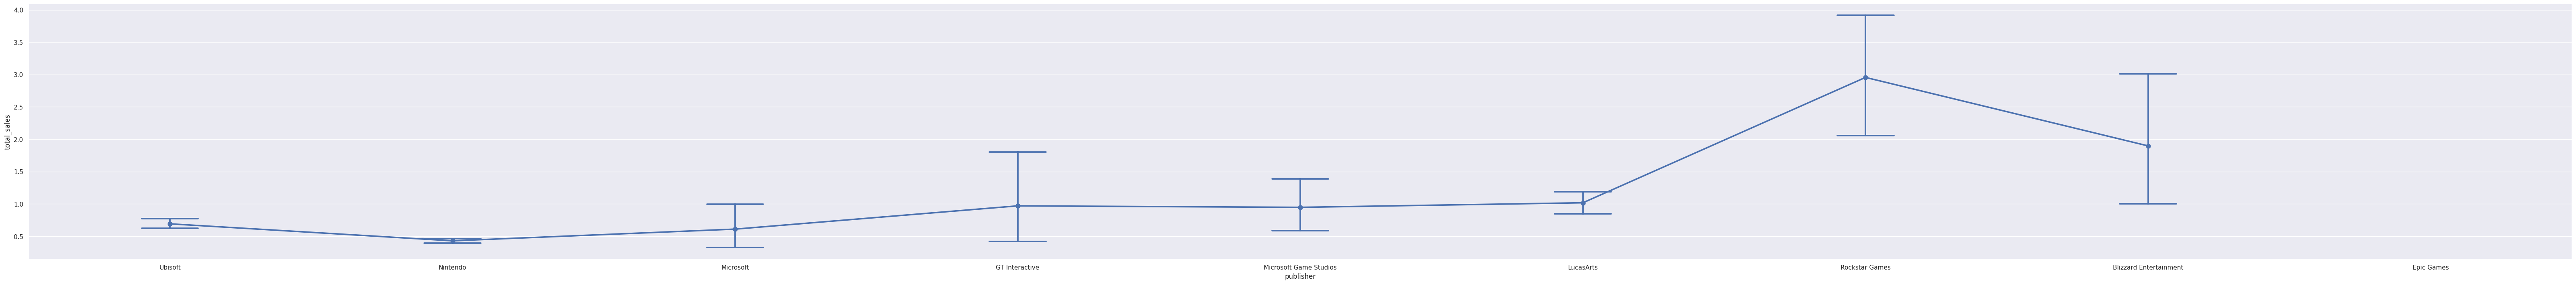

<Figure size 8170x827 with 0 Axes>

In [ ]:
ax = sns.pointplot(x=subset_df["publisher"] ,  y=subset_df["total_sales"], data=subset_df, estimator=np.mean,capsize=.2)
plt.figure()
plt.show()

In [ ]:
df_new = subset_df[subset_df["Year"]>2014]

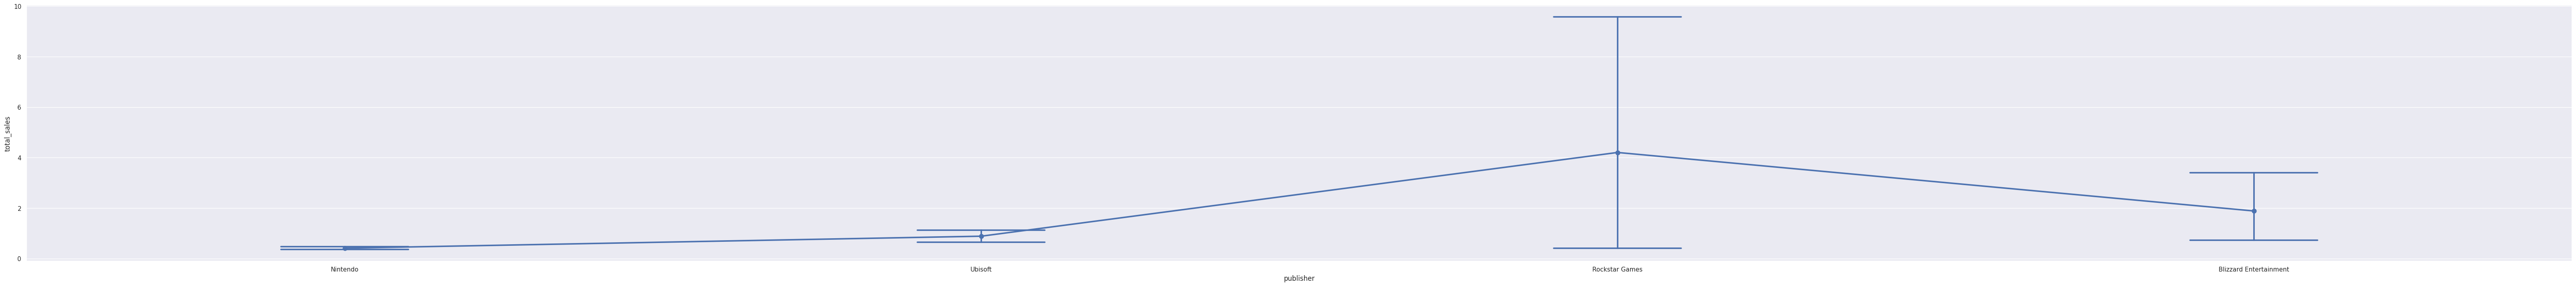

<Figure size 8170x827 with 0 Axes>

In [ ]:
ax = sns.pointplot(x=df_new["publisher"] ,  y=df_new["total_sales"], data=df_new, estimator=np.mean,capsize=.2)
plt.figure()
plt.show()

In [ ]:
temp = df_new["total_sales"].sub(df_new["total_sales"].mean()) # Soustraire la moyenne de chaque colonne à chaque valeur : centrer les valeurs

X= temp.div(temp.std()) # Divisé les valeurs de la dataframe par l'écart-type de chaque colonne


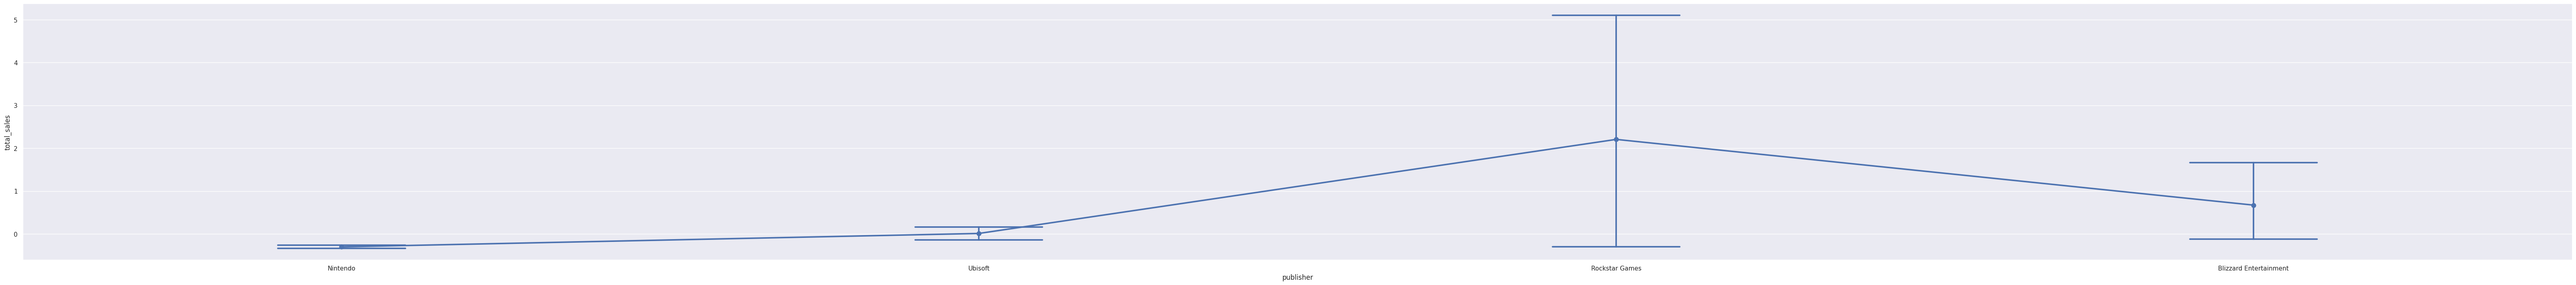

<Figure size 8170x827 with 0 Axes>

In [ ]:
ax = sns.pointplot(x=df_new["publisher"] ,  y=X, estimator=np.mean,capsize=.2)
plt.figure()
plt.show()

In [ ]:
df_new.loc[df['publisher'] == 'Rockstar Games']


,img,title,console,genre,publisher,developer,vg_score,critic_score,user_score,total_shipped,total_sales,na_sales,jp_sales,pal_sales,other_sales,release_date,last_update,Year
53,/games/boxart/full_5942658AmericaFrontccc.jpg,Red Dead Redemption 2,All,Action,Rockstar Games,Rockstar Studios,NaN,9.8,NaN,57.0,NaN,NaN,NaN,NaN,NaN,2018-10-26,2020-10-08,2018.0
288,/games/boxart/full_4653215AmericaFrontccc.jpg,Red Dead Redemption 2,PS4,Action,Rockstar Games,Rockstar Games,8.0,9.8,NaN,NaN,13.94,5.26,0.21,6.21,2.26,2018-10-26,2018-11-02,2018.0
317,/games/boxart/full_9031276AmericaFrontccc.jpg,Grand Theft Auto V,PC,Action,Rockstar Games,Rockstar North,NaN,NaN,NaN,12.6,NaN,NaN,NaN,NaN,NaN,2015-04-14,2018-11-02,2015.0
683,/games/boxart/full_1425733AmericaFrontccc.jpg,Red Dead Redemption 2,XOne,Action,Rockstar Games,Rockstar Games,NaN,NaN,NaN,NaN,5.77,3.76,NaN,1.47,0.54,2018-10-26,2018-11-02,2018.0
5243,/games/boxart/full_6235034AmericaFrontccc.jpg,L.A. Noire,PS4,Action,Rockstar Games,Team Bondi,NaN,NaN,NaN,NaN,0.60,0.18,NaN,0.32,0.10,2017-11-14,2018-06-19,2017.0
6516,/games/boxart/full_7813179AmericaFrontccc.png,L.A. Noire,NS,Action,Rockstar Games,Team Bondi,NaN,7.9,8.0,NaN,0.45,0.21,NaN,0.21,0.04,2017-11-14,2018-06-19,2017.0
9244,/games/boxart/full_6677926AmericaFrontccc.jpg,L.A. Noire,XOne,Action,Rockstar Games,Team Bondi,NaN,NaN,NaN,NaN,0.25,0.14,NaN,0.09,0.02,2017-11-14,2018-06-19,2017.0


In [ ]:
df_new.loc[df_new['publisher'] == 'Rockstar Games','na_sales'].mean()


1.9100000000000001

In [ ]:
import pandas as pd
from scipy.stats import t

def ic_total_sales(df_new,country):
  sales_values = df_new[country].dropna()
  # Calcul de la moyenne et de l'écart type
  mean_na_sales = sales_values.mean()
  std_dev_na_sales = sales_values.std()
  # Nombre d'observations
  n = len(sales_values)
  # Degrés de liberté pour la distribution t
  degrees_of_freedom = n - 1
  # Niveau de confiance (1 - alpha)
  confidence_level = 0.95
  # Calcul de l'erreur standard de la moyenne
  standard_error =  np.var(sales_values ,ddof=1)
  # Utilisation de la distribution t pour obtenir l'intervalle de confiance
  t_critical = t.ppf((1 + confidence_level) / 2, degrees_of_freedom)
  margin_of_error = t_critical * standard_error
  # Calcul de l'intervalle de confiance
  confidence_interval = (mean_na_sales - margin_of_error, mean_na_sales + margin_of_error)
  # Affichage de l'intervalle de confiance
  print(f"Intervalle de confiance à 95% pour ", country, " des jeux de 'Rockstar Games': ", confidence_interval)


In [ ]:
df_new.loc[df_new['publisher'] == 'Rockstar Games','jp_sales'].mean()

0.21

In [ ]:
ic_total_sales(df_new.loc[df_new['publisher'] == 'Rockstar Games'],'jp_sales')

Intervalle de confiance à 95% pour  jp_sales  des jeux de 'Rockstar Games':  (nan, nan)


In [ ]:
df_new.loc[df_new['publisher'] == 'Rockstar Games','other_sales'].mean()

0.592

In [ ]:
ic_total_sales(df_new.loc[df_new['publisher'] == 'Rockstar Games'],'other_sales')

Intervalle de confiance à 95% pour  other_sales  des jeux de 'Rockstar Games':  (-1.9476698666265295, 3.1316698666265297)


In [ ]:
df_new.loc[df_new['publisher'] == 'Rockstar Games','pal_sales'].mean()

1.6600000000000001

In [ ]:
ic_total_sales(df_new.loc[df_new['publisher'] == 'Rockstar Games'],'pal_sales')

Intervalle de confiance à 95% pour  pal_sales  des jeux de 'Rockstar Games':  (-17.151526165757165, 20.471526165757165)


In [ ]:
df_new_shoot = df_new.loc[df['publisher'] == 'Rockstar Games']

for plateforme in  df_new_shoot['console'].unique():
    print(plateforme)
    print(df_new_shoot.loc[df_new_shoot['console'] == plateforme,'total_sales'].mean())


All
nan
PS4
7.27
PC
nan
XOne
3.01
NS
0.45
